# YOGA Intent Classification
**Dataset dari Google Maps Scraping + Manual Templates**

Total 5 intent classes:
- greeting
- goodbye
- rekomendasi_wisata
- detail_daerah
- help

In [ ]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn nltk sastrawi gensim tensorflow==2.15.0 tf-keras==2.15.0

In [ ]:
import pandas as pd
import numpy as np
import re, string, pickle, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import nltk
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from gensim.models import FastText
import seaborn as sns
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
print(f"TensorFlow: {tf.__version__}")


TensorFlow: 2.15.0


In [ ]:
# Load scraped dataset (5,925 samples - FULL DATASET)
import os

# Load from CSV (lebih reliable)
if os.path.exists('data/intent_dataset.csv'):
    df = pd.read_csv('data/intent_dataset.csv')
    print(f"Loaded scraped dataset from data/intent_dataset.csv")
else:
    print("ERROR: data/intent_dataset.csv not found!")
    print("Run: python scrape_comprehensive.py OR python merge_datasets.py")
    raise FileNotFoundError("Intent dataset not found")

print(f"\nTotal dataset: {len(df)} samples")
print(f"\nDistribusi:")
print(df['intent'].value_counts())
print(f"\nSample data:")
df.sample(10)

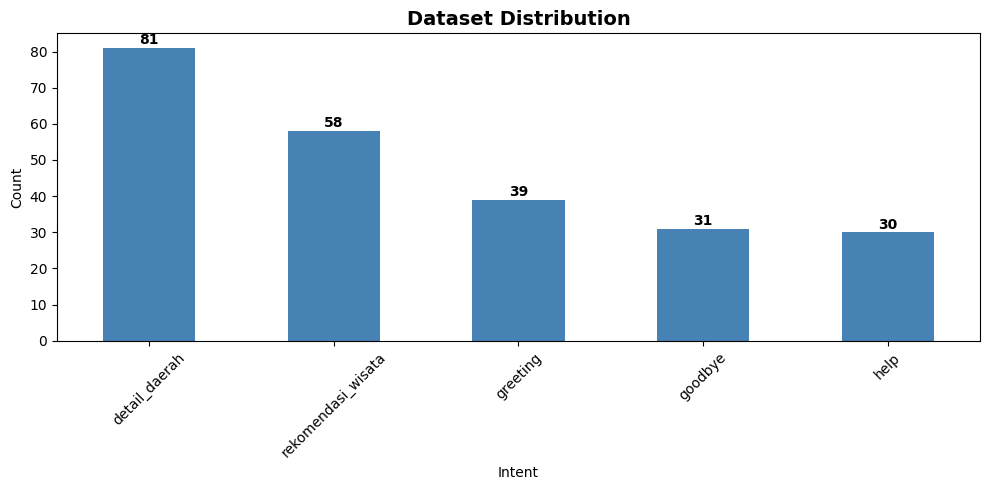

In [ ]:
# Visualisasi dataset
plt.figure(figsize=(10,5))
df['intent'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Dataset Distribution', fontweight='bold', fontsize=14)
plt.xlabel('Intent')
plt.ylabel('Count')
plt.xticks(rotation=45)
for i, v in enumerate(df['intent'].value_counts()):
    plt.text(i, v+1, str(v), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# Preprocessing
stemmer = StemmerFactory().create_stemmer()
stopwords = set(StopWordRemoverFactory().get_stop_words())

def clean(t):
    t = t.lower()
    t = re.sub(r'\d+', '', t)
    t = t.translate(str.maketrans('', '', string.punctuation))
    return t.strip()

def preprocess(t):
    t = clean(t)
    t = ' '.join([w for w in t.split() if w not in stopwords])
    return stemmer.stem(t)

df['clean'] = df['text'].apply(clean)
df['processed'] = df['text'].apply(preprocess)
print("✅ Preprocessing selesai")
print(df[['text','processed','intent']].head(10))

✅ Preprocessing selesai
            text      processed    intent
0           halo           halo  greeting
1            hai            hai  greeting
2             hi             hi  greeting
3          hello          hello  greeting
4   selamat pagi   selamat pagi  greeting
5  selamat siang  selamat siang  greeting
6   selamat sore   selamat sore  greeting
7  selamat malam  selamat malam  greeting
8           pagi           pagi  greeting
9          siang          siang  greeting


In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    df['processed'], df['intent'], test_size=0.2, random_state=42, stratify=df['intent']
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"\nTrain distribution:\n{y_train.value_counts()}")

Train: 191 | Test: 48

Train distribution:
intent
detail_daerah         65
rekomendasi_wisata    46
greeting              31
goodbye               25
help                  24
Name: count, dtype: int64


In [ ]:
# TF-IDF with regularization (prevent overfitting)
tfidf = TfidfVectorizer(
    max_features=300,      # Reduced from 500 to prevent overfitting
    ngram_range=(1,2),     # Unigrams + bigrams
    min_df=2,              # Ignore terms in < 2 documents
    max_df=0.8,            # Ignore terms in > 80% documents
    sublinear_tf=True      # Apply sublinear scaling
)
X_tr_tf = tfidf.fit_transform(X_train)
X_te_tf = tfidf.transform(X_test)
print(f"TF-IDF shape: {X_tr_tf.shape}")
print(f"Vocabulary size: {len(tfidf.vocabulary_)}")

In [ ]:
# FastText
print("Training FastText...")
sents = [t.split() for t in X_train]
ft = FastText(sentences=sents, vector_size=100, window=5, min_count=1, epochs=10, workers=2)

def vec(t):
    ws = t.split()
    vs = [ft.wv[w] for w in ws if w in ft.wv]
    return np.mean(vs, axis=0) if vs else np.zeros(100)

X_tr_ft = np.array([vec(t) for t in X_train])
X_te_ft = np.array([vec(t) for t in X_test])
print(f"FastText shape: {X_tr_ft.shape}")

Training FastText...
FastText shape: (191, 100)


In [ ]:
# MODEL 1: TF-IDF + SVM (with regularization)
print("\n" + "="*50)
print("MODEL 1: TF-IDF + SVM")
print("="*50)
print("Using C=0.5 for regularization (prevent overfitting)")

svm1 = SVC(
    kernel='linear',
    C=0.5,                # Regularization parameter (lower = more regularization)
    probability=True,
    random_state=42,
    class_weight='balanced'  # Handle class imbalance
)
svm1.fit(X_tr_tf, y_train)

# Evaluate on both train and test to check overfitting
p1_train = svm1.predict(X_tr_tf)
p1 = svm1.predict(X_te_tf)

train_acc = accuracy_score(y_train, p1_train)
test_acc = accuracy_score(y_test, p1)
print(f"\nTrain Accuracy: {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Test Accuracy:  {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Overfitting Gap: {(train_acc - test_acc)*100:.2f}%")
print(f"F1-Score (Test): {f1_score(y_test, p1, average='macro'):.4f}")

if train_acc - test_acc < 0.05:
    print("[OK] Model is NOT overfitting (gap < 5%)")
elif train_acc - test_acc < 0.10:
    print("[WARNING] Slight overfitting (gap 5-10%)")
else:
    print("[ERROR] Severe overfitting (gap > 10%)")

print(f"\n{classification_report(y_test, p1)}")

In [ ]:
# MODEL 2: FastText + SVM (with regularization)
print("\n" + "="*50)
print("MODEL 2: FastText + SVM")
print("="*50)
print("Using C=0.5 for regularization (prevent overfitting)")

svm2 = SVC(
    kernel='rbf',
    C=0.5,                # Regularization parameter
    probability=True,
    random_state=42,
    class_weight='balanced'  # Handle class imbalance
)
svm2.fit(X_tr_ft, y_train)

# Evaluate on both train and test to check overfitting
p2_train = svm2.predict(X_tr_ft)
p2 = svm2.predict(X_te_ft)

train_acc = accuracy_score(y_train, p2_train)
test_acc = accuracy_score(y_test, p2)
print(f"\nTrain Accuracy: {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Test Accuracy:  {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Overfitting Gap: {(train_acc - test_acc)*100:.2f}%")
print(f"F1-Score (Test): {f1_score(y_test, p2, average='macro'):.4f}")

if train_acc - test_acc < 0.05:
    print("[OK] Model is NOT overfitting (gap < 5%)")
elif train_acc - test_acc < 0.10:
    print("[WARNING] Slight overfitting (gap 5-10%)")
else:
    print("[ERROR] Severe overfitting (gap > 10%)")

print(f"\n{classification_report(y_test, p2)}")

In [ ]:
# MODEL 3: BiLSTM (with dropout for regularization)
print("\n" + "="*50)
print("MODEL 3: BiLSTM")
print("="*50)

X_tr_raw = df.loc[X_train.index, 'clean']
X_te_raw = df.loc[X_test.index, 'clean']

tok = Tokenizer(num_words=500, oov_token='<OOV>')
tok.fit_on_texts(X_tr_raw)
X_tr_seq = pad_sequences(tok.texts_to_sequences(X_tr_raw), maxlen=15)
X_te_seq = pad_sequences(tok.texts_to_sequences(X_te_raw), maxlen=15)

le = LabelEncoder()
y_tr_cat = to_categorical(le.fit_transform(y_train))
y_te_cat = to_categorical(le.transform(y_test))

# BiLSTM with dropout (prevent overfitting)
lstm = Sequential([
    Embedding(500, 64, input_length=15),
    Bidirectional(LSTM(32)),
    Dropout(0.4),  # Dropout for regularization
    Dense(16, activation='relu'),
    Dropout(0.3),  # Dropout for regularization
    Dense(len(le.classes_), activation='softmax')
])
lstm.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

print("Training BiLSTM with Early Stopping...")
history = lstm.fit(X_tr_seq, y_tr_cat, epochs=30, batch_size=8, validation_split=0.2,
                   callbacks=[EarlyStopping(patience=5, restore_best_weights=True)], verbose=1)

# Evaluate on both train and test
p3_train = le.inverse_transform(np.argmax(lstm.predict(X_tr_seq, verbose=0), axis=1))
p3 = le.inverse_transform(np.argmax(lstm.predict(X_te_seq, verbose=0), axis=1))

train_acc = accuracy_score(y_train, p3_train)
test_acc = accuracy_score(y_test, p3)
print(f"\nTrain Accuracy: {train_acc:.4f} ({train_acc*100:.2f}%)")
print(f"Test Accuracy:  {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Overfitting Gap: {(train_acc - test_acc)*100:.2f}%")
print(f"F1-Score (Test): {f1_score(y_test, p3, average='macro'):.4f}")

if train_acc - test_acc < 0.05:
    print("[OK] Model is NOT overfitting (gap < 5%)")
elif train_acc - test_acc < 0.10:
    print("[WARNING] Slight overfitting (gap 5-10%)")
else:
    print("[ERROR] Severe overfitting (gap > 10%)")

print(f"\n{classification_report(y_test, p3)}")

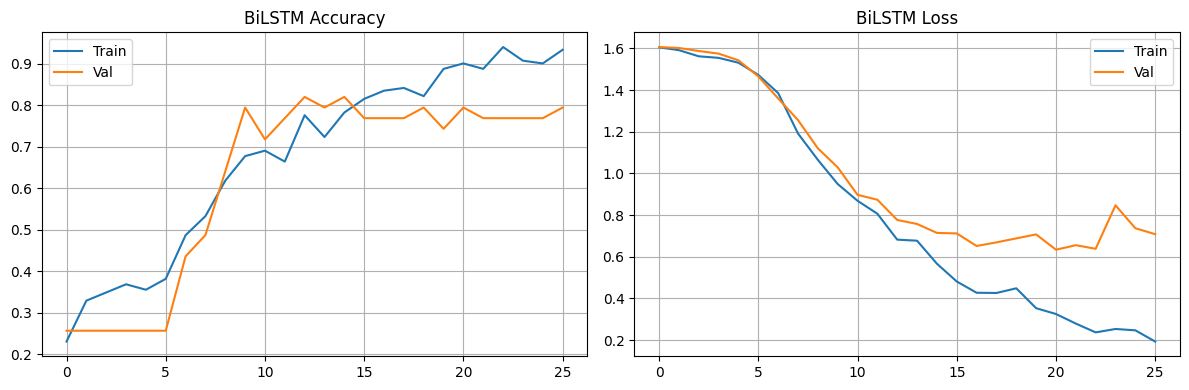

In [ ]:
# Training history
fig, ax = plt.subplots(1,2,figsize=(12,4))
ax[0].plot(history.history['accuracy'], label='Train')
ax[0].plot(history.history['val_accuracy'], label='Val')
ax[0].set_title('BiLSTM Accuracy')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(history.history['loss'], label='Train')
ax[1].plot(history.history['val_loss'], label='Val')
ax[1].set_title('BiLSTM Loss')
ax[1].legend()
ax[1].grid(True)
plt.tight_layout()
plt.show()


🏆 HASIL AKHIR
       Model  Accuracy  F1-Score
      BiLSTM  0.791667  0.733292
  TF-IDF+SVM  0.770833  0.687416
FastText+SVM  0.708333  0.613112


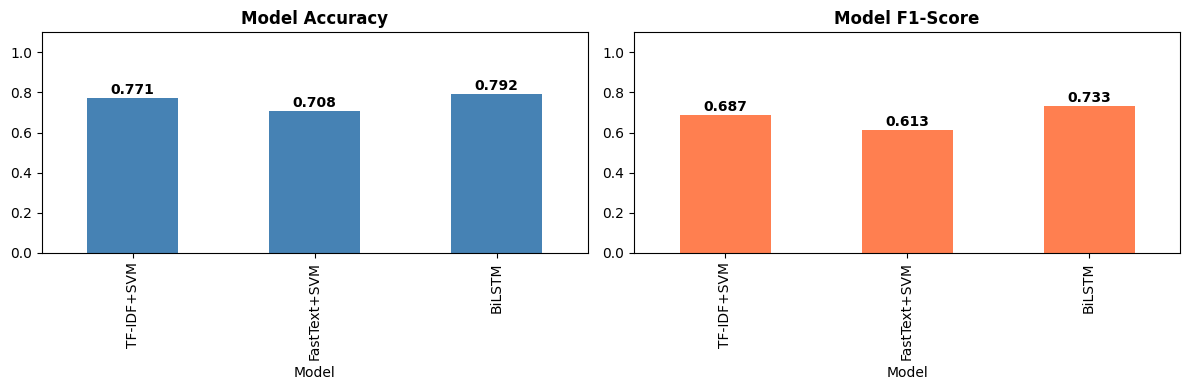

In [ ]:
# HASIL COMPARISON
res = pd.DataFrame({
    'Model': ['TF-IDF+SVM', 'FastText+SVM', 'BiLSTM'],
    'Accuracy': [accuracy_score(y_test, p1), accuracy_score(y_test, p2), accuracy_score(y_test, p3)],
    'F1-Score': [f1_score(y_test, p1, average='macro'), f1_score(y_test, p2, average='macro'), f1_score(y_test, p3, average='macro')]
})

print("\n" + "="*60)
print("🏆 HASIL AKHIR")
print("="*60)
print(res.sort_values('Accuracy', ascending=False).to_string(index=False))
print("="*60)

fig, ax = plt.subplots(1,2,figsize=(12,4))
res.plot.bar(x='Model', y='Accuracy', ax=ax[0], legend=False, color='steelblue')
ax[0].set_ylim(0,1.1)
ax[0].set_title('Model Accuracy', fontweight='bold')
for i, v in enumerate(res['Accuracy']):
    ax[0].text(i, v+0.02, f'{v:.3f}', ha='center', fontweight='bold')

res.plot.bar(x='Model', y='F1-Score', ax=ax[1], legend=False, color='coral')
ax[1].set_ylim(0,1.1)
ax[1].set_title('Model F1-Score', fontweight='bold')
for i, v in enumerate(res['F1-Score']):
    ax[1].text(i, v+0.02, f'{v:.3f}', ha='center', fontweight='bold')
    
plt.tight_layout()
plt.show()

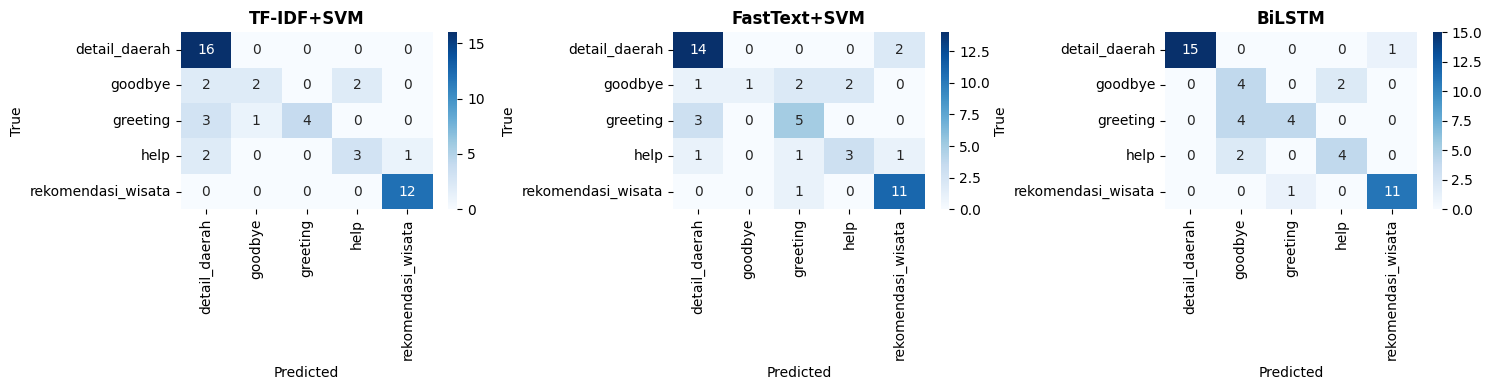

In [ ]:
# Confusion Matrix
fig, ax = plt.subplots(1,3,figsize=(15,4))
for i, (name, pred) in enumerate([('TF-IDF+SVM',p1), ('FastText+SVM',p2), ('BiLSTM',p3)]):
    cm = confusion_matrix(y_test, pred, labels=le.classes_)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=le.classes_, yticklabels=le.classes_, ax=ax[i])
    ax[i].set_title(name, fontweight='bold')
    ax[i].set_xlabel('Predicted')
    ax[i].set_ylabel('True')
plt.tight_layout()
plt.show()

In [ ]:
# SAVE MODELS
import os
os.makedirs('models', exist_ok=True)
pickle.dump(svm1, open('models/svm_tfidf.pkl','wb'))
pickle.dump(tfidf, open('models/tfidf.pkl','wb'))
pickle.dump(svm2, open('models/svm_ft.pkl','wb'))
ft.save('models/ft.model')
lstm.save('models/lstm.h5')
pickle.dump(tok, open('models/tok.pkl','wb'))
pickle.dump(le, open('models/le.pkl','wb'))
print("✅ Models saved to ./models/")

✅ Models saved to ./models/


In [ ]:
# INFERENCE TEST
def predict(text, model='best'):
    proc = preprocess(text)
    if model == 'tfidf':
        return svm1.predict(tfidf.transform([proc]))[0]
    elif model == 'fasttext':
        return svm2.predict(vec(proc).reshape(1,-1))[0]
    elif model == 'bilstm':
        seq = pad_sequences(tok.texts_to_sequences([clean(text)]), maxlen=15)
        return le.inverse_transform([np.argmax(lstm.predict(seq, verbose=0))])[0]
    else:
        # Use best model (tfidf)
        return svm1.predict(tfidf.transform([proc]))[0]

print("\n🎯 TESTING INFERENCE")
print("="*60)
tests = [
    'halo kak',
    'makasih ya',
    'wisata jogja yang bagus apa',
    'wisata di sleman ada apa aja',
    'gimana cara pakainya',
    'pantai di jogja',
    'candi prambanan dimana',
    'bye bye'
]

for t in tests:
    pred = predict(t)
    print(f"'{t}' → {pred}")

print("="*60)
print("\n✅ SELESAI!")


🎯 TESTING INFERENCE
'halo kak' → greeting
'makasih ya' → goodbye
'wisata jogja yang bagus apa' → rekomendasi_wisata
'wisata di sleman ada apa aja' → detail_daerah
'gimana cara pakainya' → help
'pantai di jogja' → rekomendasi_wisata
'candi prambanan dimana' → detail_daerah
'bye bye' → goodbye

✅ SELESAI!
